# 10 - Linear Regression

Part of the **Data Science Learning** project. Explanations, comments, and notebook messages are in English.

## Learning objectives
Train a regression model and evaluate it using MAE, RMSE, and R-squared.

## 1. Imports

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

In [7]:
dataset = load_diabetes(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(dataset.data, dataset.target, test_size=0.2, random_state=RANDOM_STATE)

## Train and evaluate

In [3]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(f"MAE:  {mean_absolute_error(y_test, pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.3f}")
print(f"R-squared: {r2_score(y_test, pred):.3f}")

MAE:  42.794
RMSE: 53.853
R-squared: 0.453


## Visualize actual vs predicted values

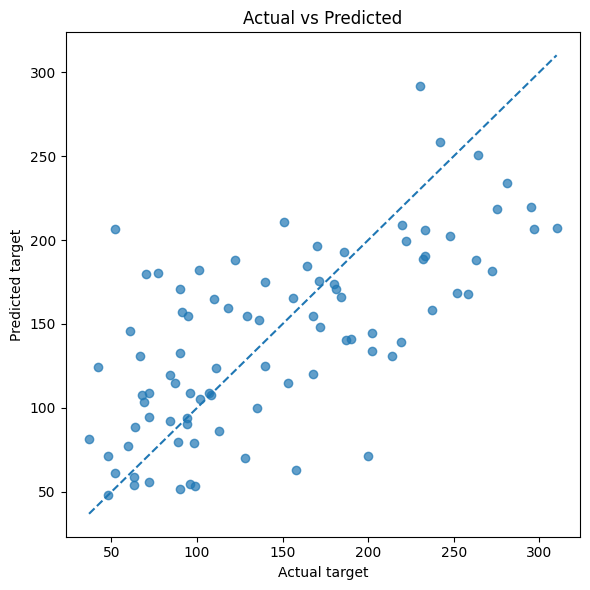

In [4]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.7)
lower = min(y_test.min(), pred.min())
upper = max(y_test.max(), pred.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.show()

In [5]:
pd.Series(model.coef_, index=dataset.feature_names).sort_values().to_frame("coefficient")

,coefficient
s1,-931.488846
sex,-241.964362
age,37.904021
s6,48.670657
s3,163.419983
s4,275.317902
bp,347.703844
s2,518.062277
bmi,542.428759
s5,736.198859


## Key takeaways
- Regression predicts numeric values.
- MAE and RMSE are error measures; lower is usually better.
- R-squared can be negative on unseen data.

## Exercises
1. Fit using only three features.
2. Compare with Ridge regression.
3. Inspect residuals.